# Klasifikasi spam SMS untuk UTS Milestone 1

Kelompok kami ingin melihat seberapa baik model bisa membedakan SMS biasa (*ham*, label 0) dan spam (label 1) dari isi satu pesan. Kami membandingkan Logistic Regression berbasis kata dengan Linear SVM yg juga membaca potongan karakter. Keduanya diuji pada SMS yg sama. Di akhir, kami mencoba mengubah ejaan beberapa pesan untuk melihat apakah prediksinya ikut berubah.

**Cara menjalankan.** Ekstrak seluruh folder tugas, lalu buka notebook ini dengan kernel Python 3.12. Ikuti [petunjuk instalasi](README.md) sekali, lalu pilih **Restart Kernel → Run All**. Kedua CSV sudah ada di `data/`. Setelah training selesai, Bapak bisa mengganti isi `pesan_sendiri` di bagian 8 dan menjalankan sel itu saja.

## 1. Persiapan

Kami memakai dua file di `data/`. `super_sms_dataset.csv` berisi SMS beserta labelnya, sedangkan `pembagian_awal.csv` mencatat pesan mana yg sejak awal masuk train, validation, atau test. Dengan begitu, orang yg menjalankan ulang notebook bisa memakai pembagian yg sama.

`SEED = 42` menetapkan pengacakan untuk fold dan model. Kami mengelompokkan berkas di `hasil/` sesuai tahap yg menghasilkannya. `simpan_tahap()` menyiapkan berkas baru dulu, lalu mengganti berkas lama sesudah penulisan selesai. Kalau Bapak menjalankan ulang bagian 8, misalnya, hanya tabel di `hasil/prediksi_sendiri/` yg diperbarui.

Sel ini menampilkan versi Python, lokasi dataset dan folder hasil, serta versi pustaka yg dipakai. Saat training selesai, versi yg dipakai tercatat bersama parameter di `hasil/model/konfigurasi.json`.

In [1]:
from pathlib import Path
from contextlib import contextmanager
from uuid import uuid4
from time import perf_counter
import sys, json, hashlib, re, unicodedata
from importlib.metadata import version
from joblib import dump
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_validate, learning_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report, PrecisionRecallDisplay)

SEED = 42
PROYEK = Path('.')
if not Path('data/pembagian_awal.csv').is_file() and Path('UTS/data/pembagian_awal.csv').is_file():
    PROYEK = Path('UTS')
DATA = PROYEK / 'data/super_sms_dataset.csv'
SPLIT_AWAL = PROYEK / 'data/pembagian_awal.csv'
for sumber in (DATA, SPLIT_AWAL):
    if not sumber.is_file():
        raise FileNotFoundError(f'{sumber.as_posix()} belum ditemukan. Ekstrak seluruh folder tugas dan buka notebook dari folder yg berisi data/.')
HASIL = PROYEK / 'hasil'

@contextmanager
def simpan_tahap(tahap):
    tujuan = HASIL / tahap
    tujuan.mkdir(parents=True, exist_ok=True)
    folder = tujuan / f'.menulis-{uuid4().hex}'
    folder.mkdir()
    try:
        yield folder
        for berkas in list(folder.iterdir()):
            berkas.replace(tujuan / berkas.name)
    finally:
        for sisa in folder.iterdir():
            sisa.unlink()
        folder.rmdir()

VERSI = {p: version(p) for p in ['numpy','pandas','scipy','scikit-learn','matplotlib','ipykernel','nbformat','nbclient','joblib']}
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
pd.set_option('display.max_colwidth', 110)
print('Python:', sys.version.split()[0])
print('Dataset:', DATA.as_posix())
print('Hasil:', HASIL.as_posix())
display(pd.Series(VERSI, name='Versi').to_frame())

Python: 3.12.14
Dataset: data/super_sms_dataset.csv
Hasil: hasil


,Versi
numpy,2.5.3
pandas,3.0.1
scipy,1.18.1
scikit-learn,1.9.1
matplotlib,3.11.2
ipykernel,7.4.0
nbformat,5.11.1
nbclient,0.11.0
joblib,1.6.0


## 2. Membaca dan memeriksa dataset

Dataset yg kami pakai adalah **Super SMS** dari Salman, Ikram, dan Kaafar. Satu baris memuat isi pesan di `SMSes` dan labelnya di `Labels`. Dataset ini menggabungkan beberapa koleksi SMS historis. Kami membatasi kesimpulan pada pesan yg diuji di sini. [Artikel sumber](https://doi.org/10.1109/ACCESS.2024.3364671) · [Versi CSV dari peneliti](https://github.com/smspamresearch/spstudy/blob/a0889f36fb59e23a7f853a6932485d93d18b8afc/Data/super_sms_dataset.csv)

Sebelum membaca CSV, kami mencocokkan SHA-256 file dengan versi acuan. `pd.read_csv()` memakai encoding `cp1252` karena file asal mengandung byte yg gagal dibaca sebagai UTF-8. Karakter yg gagal dibaca ditandai `�`. Isian kosong juga kami pertahankan dulu supaya bisa diperiksa pada bagian 3. Kolom `id_baris` menyimpan nomor baris asal untuk menelusuri hasil prediksi.

Di bawah akan terlihat 67.010 baris mentah, lima SMS pertama, dan jumlah per label. Ada dua baris dengan label kosong.

In [2]:
sha256 = hashlib.sha256(DATA.read_bytes()).hexdigest()
assert sha256 == 'ba825b468b59fb229cc56c15a6c2d14d593a88051d54ea2f402166bf2ab894d3', 'Versi dataset berubah; periksa sumber dahulu.'
raw = pd.read_csv(DATA, encoding='cp1252', encoding_errors='replace', dtype=str, keep_default_na=False)
assert raw.columns.tolist() == ['SMSes', 'Labels']
raw.insert(0, 'id_baris', np.arange(len(raw)))
print('Jumlah baris mentah:', len(raw))
print('SHA256:', sha256)
display(raw.head())
display(raw['Labels'].replace('', '(kosong)').value_counts().rename_axis('Label').to_frame('Jumlah'))

Jumlah baris mentah: 67010
SHA256: ba825b468b59fb229cc56c15a6c2d14d593a88051d54ea2f402166bf2ab894d3


,id_baris,SMSes,Labels
0,0,There be an update for your delivery CC 01728161E due 09.06.2020 Tap here http://olo.me/3i6xF,1
1,1,watch your favorite english movies of all genre like fast furious the thaw stepup in just rs month to s...,1
2,2,aur what is the status for fms,0
3,3,hi shalini sundi thank you for dialling special offer for you is talk to stars to subscribe dial toll fr...,1
4,4,m tryin to understand too...,0


,Jumlah
Label,
0,40830
1,26178
(kosong),2


## 3. Preprocessing dan pencegahan kebocoran data

Kami menyiapkan dua bentuk teks dengan kegunaan berbeda.

1. **Teks untuk model.** `bersihkan()` menyamakan bentuk Unicode dengan NFKC dan merapikan spasi. Angka dan tanda baca tetap masuk ke model. Kami mencatat dan menyisihkan baris dengan teks kosong, label di luar 0/1, atau karakter `�`. Setelah itu, kode mengecek teks yg sama dengan mengabaikan kapitalisasi. Kalau labelnya bertentangan, seluruh kelompok teks itu dikeluarkan. Kalau labelnya sama, kami cukup menyimpan satu salinan.
2. **Kunci untuk membagi pesan.** `kunci_kelompok()` menyeragamkan URL dan email pada teks asal. Saat membentuk kolom `kelompok`, kode juga mengabaikan angka, spasi, dan tanda baca. Dengan begitu, dua SMS promosi yg hanya berbeda nominal bisa dikenali sebagai satu pola.

`pd.read_csv(SPLIT_AWAL)` membaca pembagian awal berdasarkan ID baris. Kalau ada pola yg juga muncul di test, kami keluarkan salinannya dari train dan validation. Kalau pola train juga muncul di validation, kami keluarkan salinannya dari train. `isdisjoint()` memeriksa hasil pemisahan ini. Aturan tersebut hanya mengenali kemiripan yg tertangkap oleh kunci tadi.

Pada tabel alasan, **66.894 pesan** lolos pembersihan awal. Setelah 606 pesan berpola lintas bagian dikeluarkan, tersisa **66.288 pesan**. Tabel pembagian menunjukkan jumlah akhir per kelas. ID pembagian dan alasan pengeluaran tersimpan di `hasil/preprocessing/`.

In [3]:
def bersihkan(teks):
    return ' '.join(unicodedata.normalize('NFKC', teks).split())

alasan = pd.Series('', index=raw.index)
alasan.loc[raw['Labels'].isin(['0','1']) == False] = 'label tidak valid'
alasan.loc[raw['SMSes'].str.strip().eq('')] = 'teks kosong'
alasan.loc[raw['SMSes'].str.contains('�', regex=False)] = 'decoding bermasalah'
data = raw.loc[alasan.eq('')].copy()
data['teks'] = data['SMSes'].map(bersihkan)
data['label'] = data['Labels'].astype(int)
data['kunci'] = data['teks'].str.casefold()
konflik = data.groupby('kunci')['label'].nunique()
mask_konflik = data['kunci'].isin(konflik[konflik > 1].index)
alasan.loc[data.index[mask_konflik]] = 'label bertentangan'
data = data.loc[~mask_konflik].copy()
duplikat = data.duplicated('kunci')
alasan.loc[data.index[duplikat]] = 'duplikat teks normalisasi'
data = data.loc[~duplikat].reset_index(drop=True)
assert data['teks'].str.len().gt(0).all()

def kunci_kelompok(teks):
    teks = re.sub(r'https?://\S+|www\.\S+', '<url>', teks.casefold())
    teks = re.sub(r'\b[\w.+-]+@[\w.-]+\.\w+\b', '<email>', teks)
    return re.sub(r'\d+', '<angka>', teks)

data['kelompok'] = data['SMSes'].map(kunci_kelompok).str.replace('<angka>', '', regex=False).str.replace(r'[^a-z]', '', regex=True)
split_awal = pd.read_csv(SPLIT_AWAL).set_index('id_baris')['split']
data['split'] = data['id_baris'].map(split_awal)
assert data['split'].notna().all()
test = data.loc[data['split'].eq('test')].copy()
lintas_test = ~data['split'].eq('test') & data['kelompok'].isin(set(test['kelompok']))
val = data.loc[data['split'].eq('validation') & ~lintas_test].copy()
lintas_val = data['split'].eq('train') & data['kelompok'].isin(set(val['kelompok']))
karantina = data.loc[lintas_test | lintas_val].copy()
data = data.loc[~(lintas_test | lintas_val)].copy()
train = data.loc[data['split'].eq('train')].reset_index(drop=True)
val = val.reset_index(drop=True)
test = test.reset_index(drop=True)
print('Pesan dikeluarkan karena pola lintas pembagian:',len(karantina))
for a,b in [(train,val), (train,test), (val,test)]:
    assert set(a['kelompok']).isdisjoint(b['kelompok'])
    assert set(a['kunci']).isdisjoint(b['kunci'])

audit = raw.loc[alasan.ne(''), ['id_baris','SMSes','Labels']].assign(alasan=alasan[alasan.ne('')])
manifest = pd.concat([d[['id_baris','kelompok']].assign(split=s) for s,d in [('train',train),('validation',val),('test',test)]])
with simpan_tahap('preprocessing') as folder:
    karantina.to_csv(folder / 'pola_lintas_split_dikeluarkan.csv', index=False)
    audit.to_csv(folder / 'baris_dikeluarkan.csv', index=False)
    manifest.to_csv(folder / 'pembagian_data.csv', index=False)
display(alasan.replace('', 'dipakai').value_counts().to_frame('Jumlah'))
jumlah_split = pd.DataFrame([{'Bagian':s, 'Jumlah':len(d), 'Ham':d['label'].eq(0).sum(), 'Spam':d['label'].eq(1).sum()} for s,d in [('train',train),('validation',val),('test',test)]]).set_index('Bagian')
jumlah_split['Persentase spam'] = jumlah_split['Spam'] / jumlah_split['Jumlah'] * 100
display(jumlah_split.round(2))
print('Jumlah setelah pengolahan:',len(data))
print('Kelompok tidak tumpang tindih. Test tidak dipakai untuk pemilihan atau evaluasi UTS.')
display(raw[['SMSes']].head(3).assign(setelah_preprocessing=raw['SMSes'].head(3).map(bersihkan)))

Pesan dikeluarkan karena pola lintas pembagian: 606


,Jumlah
dipakai,66894
duplikat teks normalisasi,95
decoding bermasalah,19
label tidak valid,1
teks kosong,1


,Jumlah,Ham,Spam,Persentase spam
Bagian,,,,
train,46301,28181,18120,39.14
validation,9955,6049,3906,39.24
test,10032,6187,3845,38.33


Jumlah setelah pengolahan: 66288
Kelompok tidak tumpang tindih. Test tidak dipakai untuk pemilihan atau evaluasi UTS.


,SMSes,setelah_preprocessing
0,There be an update for your delivery CC 01728161E due 09.06.2020 Tap here http://olo.me/3i6xF,There be an update for your delivery CC 01728161E due 09.06.2020 Tap here http://olo.me/3i6xF
1,watch your favorite english movies of all genre like fast furious the thaw stepup in just rs month to s...,watch your favorite english movies of all genre like fast furious the thaw stepup in just rs month to subs...
2,aur what is the status for fms,aur what is the status for fms


## 4. Mengenal SMS pada data train

Sebelum training, kami melihat jumlah ham dan spam, panjang pesannya, serta keberadaan URL. `str.len()` menghitung jumlah karakter. `str.contains()` mencari awalan `http://`, `https://`, atau `www.`, lalu `crosstab()` menghitung pesan dengan dan tanpa URL di tiap kelas. Semua hitungan ini memakai train.

Pada tabel panjang pesan, median ham adalah **50 karakter** dan median spam **134 karakter**. Ada juga ham yg memuat URL. Jadi, keberadaan tautan saja belum cukup untuk memutuskan sebuah SMS adalah spam.

Sel ini menampilkan tabel dan dua grafik yg disimpan sebagai `hasil/eda/eda.png`. Histogram panjang SMS ditampilkan sampai persentil ke-99 agar sebaran utamanya terbaca. Pesan yg lebih panjang tetap ikut dihitung dan dilatih.

,count,mean,std,min,25%,50%,75%,max
kelas,,,,,,,,
Ham,28181.0,65.6,57.3,3.0,31.0,50.0,82.0,1471.0
Spam,18120.0,142.3,57.7,19.0,118.0,134.0,150.0,2539.0


,Tanpa URL terlihat,Dengan URL terlihat
kelas,,
Ham,28168,13
Spam,14057,4063


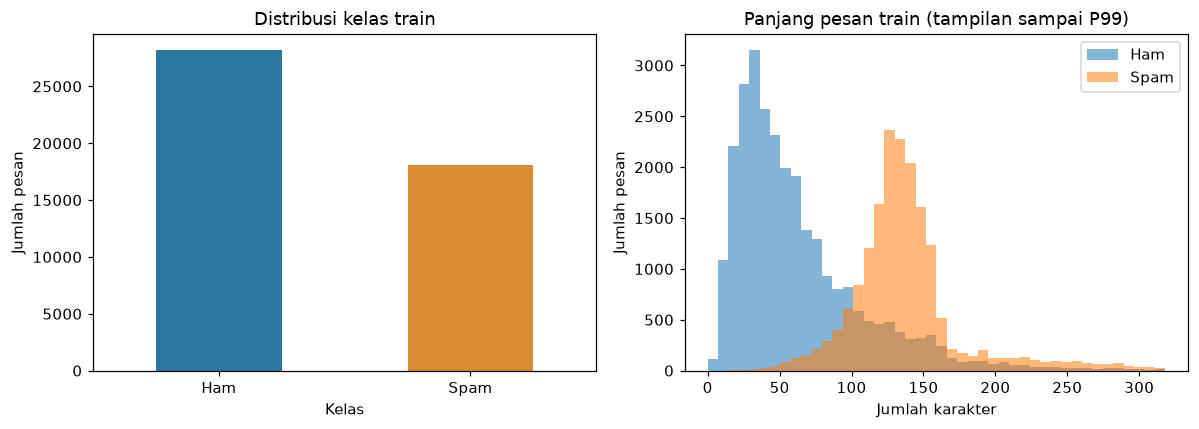

Pada train terdapat **46,301 pesan**, dengan **39.14% spam**. Median panjang ham adalah **50 karakter**, sedangkan spam **134 karakter**. Tabel URL menunjukkan komposisi yang perlu diperhatikan ketika membaca kesalahan model. Perbedaan ini merupakan karakteristik sampel train, belum membuktikan penyebab sebuah pesan menjadi spam.

In [4]:
eda = train.assign(kelas=train['label'].map({0:'Ham',1:'Spam'}), panjang=train['teks'].str.len(),
                   url=train['teks'].str.contains(r'https?://|www\.', case=False, regex=True))
display(eda.groupby('kelas')['panjang'].describe().round(1))
tabel_url = pd.crosstab(eda['kelas'], eda['url']).reindex(columns=[False,True], fill_value=0)
tabel_url.columns = ['Tanpa URL terlihat','Dengan URL terlihat']
display(tabel_url)
fig, axes = plt.subplots(1,2,figsize=(11,4))
eda['kelas'].value_counts().reindex(['Ham','Spam']).plot.bar(ax=axes[0], color=['#2878a0','#db8b32'], rot=0)
axes[0].set(title='Distribusi kelas train', ylabel='Jumlah pesan', xlabel='Kelas')
batas = eda['panjang'].quantile(.99)
for kelas in ['Ham','Spam']:
    axes[1].hist(eda.loc[eda['kelas'].eq(kelas),'panjang'], bins=np.linspace(0,batas,45), alpha=.55, label=kelas)
axes[1].set(title='Panjang pesan train (tampilan sampai P99)', xlabel='Jumlah karakter', ylabel='Jumlah pesan')
axes[1].legend(); fig.tight_layout()
with simpan_tahap('eda') as folder:
    fig.savefig(folder / 'eda.png')
plt.show()
median = eda.groupby('kelas')['panjang'].median()
display(Markdown(f'Pada train terdapat **{len(train):,} pesan**, dengan **{train.label.mean():.2%} spam**. Median panjang ham adalah **{median["Ham"]:.0f} karakter**, sedangkan spam **{median["Spam"]:.0f} karakter**. Tabel URL menunjukkan komposisi yang perlu diperhatikan ketika membaca kesalahan model. Perbedaan ini merupakan karakteristik sampel train, belum membuktikan penyebab sebuah pesan menjadi spam.'))

## 5. Menyiapkan fitur dan model

Model perlu masukan berupa angka. `fitur_kata()` menyiapkan TF-IDF untuk satu kata dan pasangan kata berurutan. Misalnya, dari `claim prize` model bisa membaca `claim`, `prize`, dan pasangan `claim prize`. Kata yg muncul di banyak SMS latih mendapat bobot IDF lebih kecil. Kami memakai `min_df=2` agar fitur muncul di sedikitnya dua SMS latih, dan `sublinear_tf=True` agar pengulangan kata dalam satu SMS tidak menaikkan bobotnya secara lurus.

| Peran | Fitur dan alasan pemilihan |
|---|---|
| Baseline · Logistic Regression | TF-IDF kata, maksimal 30.000 fitur. Kami memakai model linear ini sebagai pembanding awal untuk klasifikasi ham/spam. |
| Kandidat · Linear SVM | `FeatureUnion` menggabungkan fitur kata tadi dengan maksimal 50.000 potongan karakter sepanjang 3–5 karakter. Kami ingin melihat apakah potongan yg masih terbaca saat ejaan berubah bisa membantu klasifikasi. |

Kedua model memakai `C=1.0`. Karena jenis model dan fiturnya berubah bersamaan, hasil nanti membandingkan kedua konfigurasi secara utuh. `Pipeline` memastikan kosakata dan bobot IDF dipelajari dari bagian latih tiap fold.

Di sel ini, `StratifiedGroupKFold` menyiapkan tiga fold dengan kelompok SMS terpisah sambil mengusahakan proporsi kelas yg mirip. Tabel di bawah menunjukkan jumlah SMS latih dan validasi per fold. Kedua model nanti memakai pembagian ini.

In [5]:
def fitur_kata():
    return TfidfVectorizer(ngram_range=(1,2), min_df=2, max_df=1.0,
                           max_features=30000, sublinear_tf=True)

model = {
    'Logistic Regression kata': Pipeline([('tfidf',fitur_kata()),
        ('model',LogisticRegression(C=1.0,max_iter=1000,random_state=SEED))]),
    'SVM kata-karakter': Pipeline([('tfidf',FeatureUnion([
        ('kata',fitur_kata()),
        ('karakter',TfidfVectorizer(analyzer='char',ngram_range=(3,5),min_df=2,
            max_features=50000,sublinear_tf=True))])),
        ('model',LinearSVC(C=1.0,dual='auto',max_iter=5000,random_state=SEED))])
}
X_train, y_train = train['teks'], train['label']
X_val, y_val = val['teks'], val['label']
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
folds = list(cv.split(X_train, y_train, groups=train['kelompok']))
for latih, valid in folds:
    assert set(train.iloc[latih]['kelompok']).isdisjoint(train.iloc[valid]['kelompok'])
display(pd.DataFrame([{'Fold':i+1, 'Latih':len(a), 'Validasi':len(b)} for i,(a,b) in enumerate(folds)]))

,Fold,Latih,Validasi
0,1,30867,15434
1,2,30867,15434
2,3,30868,15433


## 6. Training dan validasi

`cross_validate()` melatih tiap model tiga kali. Setiap kali, dua fold dipakai untuk belajar dan satu fold untuk validasi. Kami memilih **macro-F1** sebagai metrik utama supaya F1 ham dan F1 spam punya bobot yg sama. Kolom `CV mean` dan `CV std` merangkum rata-rata dan simpangan baku skor pada tiga fold tadi.

Sesudah CV, `clone(pipeline).fit(X_train, y_train)` melatih salinan baru tiap pipeline pada seluruh 46.301 SMS train. `predict(X_val)` lalu memberi prediksi untuk 9.955 SMS validation yg terpisah. Dari sini kami menghitung akurasi, macro-F1, serta precision, recall, dan F1 khusus spam. Recall spam menjawab berapa banyak spam yg tertangkap. `FP rate ham` menunjukkan bagian SMS biasa yg keliru ditandai spam.

Tabel di bawah menyandingkan baseline dan kandidat, termasuk jumlah fitur dan waktu fit. Di `hasil/evaluasi/`, `cv_per_fold.csv` berisi skor tiap fold dan `hasil_validasi.csv` berisi tabel perbandingannya. `dump()` menyimpan kedua pipeline terlatih di `hasil/model/` bersama `konfigurasi.json`. Tiap file `.joblib` memuat TF-IDF beserta model klasifikasinya. Untuk uji pesan di bagian 8, kami memakai SVM yg sudah ditetapkan sebagai kandidat awal.

In [6]:
hasil_cv, hasil_val, terlatih, prediksi = [], [], {}, {}
for nama, pipeline in model.items():
    print('Mulai:',nama, flush=True)
    skor = cross_validate(pipeline, X_train, y_train, cv=folds,
                          scoring='f1_macro', return_train_score=True, n_jobs=1, error_score='raise')
    for i in range(3):
        hasil_cv.append({'Model':nama,'Fold':i+1, 'F1 train':skor['train_score'][i],
                         'F1 validasi CV':skor['test_score'][i], 'Detik fit':skor['fit_time'][i]})
    mulai = perf_counter()
    terlatih[nama] = clone(pipeline).fit(X_train,y_train)
    detik = perf_counter()-mulai
    prediksi[nama] = terlatih[nama].predict(X_val)
    p = prediksi[nama]
    tn,fp,fn,tp = confusion_matrix(y_val,p,labels=[0,1]).ravel()
    hasil_val.append({'Model':nama,'Macro-F1':f1_score(y_val,p,average='macro'),
        'Accuracy':accuracy_score(y_val,p),'Precision spam':precision_score(y_val,p,zero_division=0),
        'Recall spam':recall_score(y_val,p,zero_division=0),'F1 spam':f1_score(y_val,p,zero_division=0),
        'FP rate ham':fp/(tn+fp),'Detik fit':detik,
        'Jumlah fitur':len(terlatih[nama].named_steps['tfidf'].get_feature_names_out())})
    print(f'Selesai {nama}; mean CV macro-F1 = {skor["test_score"].mean():.4f}',flush=True)

cv_detail = pd.DataFrame(hasil_cv)
cv_ringkas = cv_detail.groupby('Model')['F1 validasi CV'].agg(['mean','std'])
tabel_hasil = pd.DataFrame(hasil_val).set_index('Model').join(cv_ringkas.rename(columns={'mean':'CV mean','std':'CV std'}))
terpilih = 'SVM kata-karakter'
with simpan_tahap('evaluasi') as folder:
    cv_detail.to_csv(folder / 'cv_per_fold.csv', index=False)
    tabel_hasil.to_csv(folder / 'hasil_validasi.csv')
konfigurasi = {nama:{k:str(v) for k,v in p.get_params(deep=True).items()} for nama,p in model.items()}
with simpan_tahap('model') as folder:
    dump(terlatih['Logistic Regression kata'], folder / 'logistic_regression_kata.joblib', protocol=5)
    dump(terlatih[terpilih], folder / 'svm_kata_karakter.joblib', protocol=5)
    (folder / 'konfigurasi.json').write_text(json.dumps({'seed':SEED,'sha256':sha256,'python':sys.version.split()[0],
        'versi':VERSI,'parameter':konfigurasi,'kandidat_tetap':terpilih},indent=2),encoding='utf-8')
print('Kandidat yang diuji:',terpilih)
display(tabel_hasil.round(4))

Mulai: Logistic Regression kata


Selesai Logistic Regression kata; mean CV macro-F1 = 0.9820


Mulai: SVM kata-karakter


Selesai SVM kata-karakter; mean CV macro-F1 = 0.9909


Kandidat yang diuji: SVM kata-karakter


,Macro-F1,Accuracy,Precision spam,Recall spam,F1 spam,FP rate ham,Detik fit,Jumlah fitur,CV mean,CV std
Model,,,,,,,,,,
Logistic Regression kata,0.9798,0.9808,0.9861,0.9647,0.9753,0.0088,1.8794,30000,0.9820,0.0013
SVM kata-karakter,0.9897,0.9902,0.9925,0.9823,0.9874,0.0048,9.8226,80000,0.9909,0.0014


## 7. Membaca confusion matrix dan memeriksa skor train

Pada kedua matriks, baris menunjukkan label asli dan kolom menunjukkan prediksi. **Ham → Spam** berarti SMS biasa keliru ditandai spam (FP). **Spam → Ham** berarti spam lolos (FN). Pada validation yg sama, baseline menghasilkan 53 FP dan 138 FN. Pada kandidat SVM, jumlahnya turun menjadi 29 FP dan 69 FN. `classification_report()` merinci precision, recall, F1, dan jumlah SMS per kelas. Kalau ingin memeriksa pesan mana yg salah, ID dan prediksinya ada di `hasil/evaluasi/prediksi_validasi.csv`.

Skor train SVM mencapai 1,0. Untuk memeriksanya, kami membandingkan `predict(X_train)` dengan label seluruh SMS yg dipakai belajar. `decision_function()` memberi skor terhadap batas keputusan. Setelah tandanya disesuaikan dengan label asli, skor antara 0 dan 1 berarti prediksi sudah benar tetapi masih berada di dalam margin SVM.

Terakhir, kami menghitung ulang IDF kata dan karakter dari dokumen train. `np.allclose()` mencocokkannya dengan IDF pipeline. Di bawah matriks dan laporan per kelas akan terlihat jumlah kesalahan train, hasil pemeriksaan IDF, dan jumlah SMS dengan margin di bawah 1. Untuk menilai kinerja pada pesan lain, kami memakai CV dan validation.

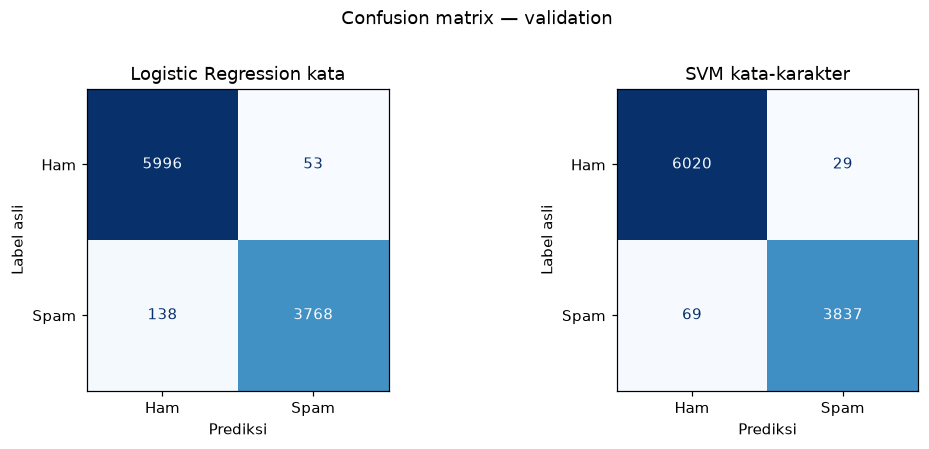

Laporan kandidat SVM: SVM kata-karakter
              precision    recall  f1-score   support

         Ham     0.9887    0.9952    0.9919      6049
        Spam     0.9925    0.9823    0.9874      3906

    accuracy                         0.9902      9955
   macro avg     0.9906    0.9888    0.9897      9955
weighted avg     0.9902    0.9902    0.9901      9955



SVM menghasilkan **29 FP** dan **69 FN** pada validation. Hasil dibandingkan dengan baseline pada tabel sebelumnya.

Kesalahan pada seluruh train: 0 dari 46301
Macro-F1 train: 1.0


kata : IDF cocok dengan dokumen train saja; 30000 fitur


karakter : IDF cocok dengan dokumen train saja; 50000 fitur
Jumlah prediksi train benar tetapi margin bertanda < 1: 6300
Klasifikasi benar tidak berarti seluruh penalti margin SVM bernilai nol.


In [7]:
fig, axes = plt.subplots(1,2,figsize=(10,4))
for ax,(nama,p) in zip(axes.flat,prediksi.items()):
    ConfusionMatrixDisplay.from_predictions(y_val,p,labels=[0,1],display_labels=['Ham','Spam'],
        cmap='Blues', colorbar=False, ax=ax)
    ax.set(title=nama, xlabel='Prediksi',ylabel='Label asli')
fig.suptitle('Confusion matrix — validation', y=1.01)
fig.tight_layout()
with simpan_tahap('evaluasi') as folder:
    fig.savefig(folder / 'confusion_matrix.png', bbox_inches='tight')
plt.show()
print('Laporan kandidat SVM:',terpilih)
print(classification_report(y_val,prediksi[terpilih],labels=[0,1],target_names=['Ham','Spam'],digits=4,zero_division=0))
laporan = pd.DataFrame(classification_report(y_val,prediksi[terpilih],labels=[0,1],target_names=['Ham','Spam'],output_dict=True,zero_division=0)).T
tn,fp,fn,tp = confusion_matrix(y_val,prediksi[terpilih],labels=[0,1]).ravel()
display(Markdown(f'SVM menghasilkan **{fp} FP** dan **{fn} FN** pada validation. Hasil dibandingkan dengan baseline pada tabel sebelumnya.'))
evaluasi = val[['id_baris','teks','label']].copy()
for nama,p in prediksi.items(): evaluasi['prediksi '+nama] = p
with simpan_tahap('evaluasi') as folder:
    laporan.to_csv(folder / 'classification_report.csv')
    evaluasi.to_csv(folder / 'prediksi_validasi.csv', index=False)
svm = terlatih[terpilih]
pred_train = svm.predict(X_train)
margin_train = svm.decision_function(X_train)
assert np.array_equal((margin_train > 0).astype(int),pred_train)
print('Kesalahan pada seluruh train:',int((pred_train != y_train).sum()),'dari',len(y_train))
print('Macro-F1 train:',f1_score(y_train,pred_train,average='macro'))
for nama,vectorizer in svm.named_steps['tfidf'].transformer_list:
    fitur = vectorizer.transform(X_train)
    df = np.asarray((fitur != 0).sum(axis=0)).ravel()
    idf_train = np.log((1+len(X_train))/(1+df))+1
    assert np.allclose(vectorizer.idf_,idf_train)
    print(nama,': IDF cocok dengan dokumen train saja;',len(vectorizer.vocabulary_),'fitur')
print('Jumlah prediksi train benar tetapi margin bertanda < 1:',int((((2*y_train-1)*margin_train)<1).sum()))
print('Klasifikasi benar tidak berarti seluruh penalti margin SVM bernilai nol.')


### Learning curve berdasarkan jumlah SMS latih

`learning_curve()` melatih salinan SVM dengan 25%, 50%, 75%, lalu 100% dari bagian latih tiap fold. Kami ingin melihat perubahan skor ketika jumlah contoh bertambah. Sumbu mendatar menunjukkan jumlah SMS latih per fold. Dua garis menunjukkan rata-rata macro-F1 train dan validasi CV, dengan pita selebar satu simpangan baku di tiap sisi.

Pada kurva ini, skor CV naik dari **0,9876** pada 7.716 SMS menjadi **0,9909** pada 30.867 SMS per fold. Skor train tetap 1,0. Jadi, tambahan data masih diikuti kenaikan skor CV pada pembagian yg kami pakai. Untuk tiga fold ini, kurva memakai simpangan baku NumPy (`ddof=0`) dan tabel CV di bagian 6 memakai bawaan pandas (`ddof=1`). Itu sebabnya angka simpangan bakunya bisa sedikit berbeda.

Di `hasil/learning_curve/`, `learning_curve.png` memuat grafik dan `learning_curve.csv` memuat angka per ukuran data latih.

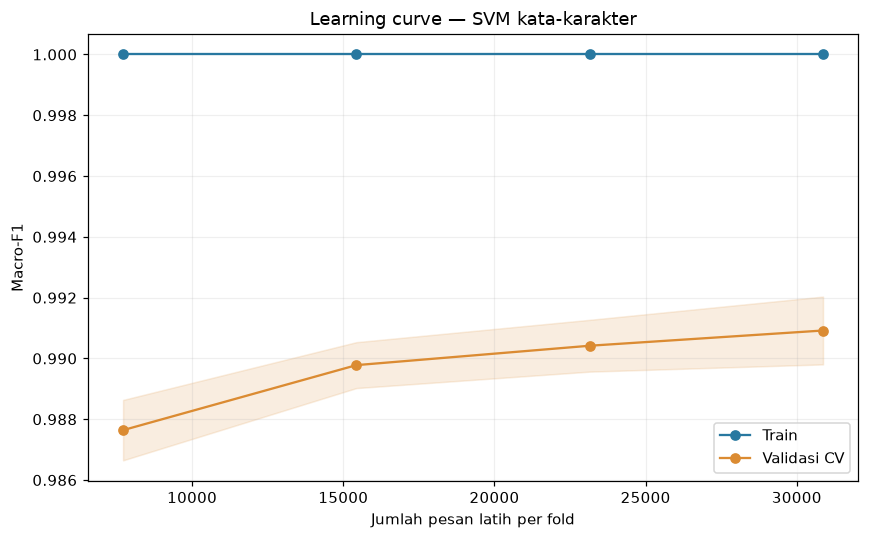

,Jumlah latih per fold,Train mean,Train std,CV mean,CV std
0,7716,1.0,0.0,0.9876,0.0010
1,15433,1.0,0.0,0.9898,0.0008
2,23150,1.0,0.0,0.9904,0.0009
3,30867,1.0,0.0,0.9909,0.0011


Pada ukuran terbesar, rata-rata macro-F1 train adalah **1.0000** dan validasi CV **0.9909**, dengan selisih **0.0091**. Perubahan skor CV dari ukuran terkecil ke terbesar adalah **+0.0033**. Angka ini berasal dari pelatihan ulang pada fold yang sama. Pemeriksaan berikutnya akan menggunakan contoh kesalahan untuk menentukan bagian pengolahan yang perlu diperbaiki.

Evaluasi dihitung dari eksekusi lokal ini.
Folder learning curve: hasil/learning_curve


In [8]:
ukuran, skor_train, skor_cv = learning_curve(model[terpilih],X_train,y_train,cv=folds,
    train_sizes=[0.25,0.5,0.75,1.0],scoring='f1_macro',shuffle=True,random_state=SEED,
    n_jobs=1,error_score='raise')
kurva = pd.DataFrame({'Jumlah latih per fold':ukuran,'Train mean':skor_train.mean(axis=1),
    'Train std':skor_train.std(axis=1),'CV mean':skor_cv.mean(axis=1),'CV std':skor_cv.std(axis=1)})
fig, ax = plt.subplots(figsize=(8,5))
for label,skor,warna in [('Train',skor_train,'#2878a0'),('Validasi CV',skor_cv,'#db8b32')]:
    rata,sd = skor.mean(axis=1),skor.std(axis=1)
    ax.plot(ukuran,rata,'o-',label=label,color=warna)
    ax.fill_between(ukuran,rata-sd,rata+sd,alpha=.15,color=warna)
ax.set(xlabel='Jumlah pesan latih per fold',ylabel='Macro-F1',title='Learning curve — '+terpilih)
ax.legend(); ax.grid(alpha=.2); fig.tight_layout()
with simpan_tahap('learning_curve') as folder:
    kurva.to_csv(folder / 'learning_curve.csv', index=False)
    fig.savefig(folder / 'learning_curve.png')
plt.show()
display(kurva.round(4))
gap = skor_train[-1].mean()-skor_cv[-1].mean()
display(Markdown(f'Pada ukuran terbesar, rata-rata macro-F1 train adalah **{skor_train[-1].mean():.4f}** dan validasi CV **{skor_cv[-1].mean():.4f}**, dengan selisih **{gap:.4f}**. Perubahan skor CV dari ukuran terkecil ke terbesar adalah **{skor_cv[-1].mean()-skor_cv[0].mean():+.4f}**. Angka ini berasal dari pelatihan ulang pada fold yang sama. Pemeriksaan berikutnya akan menggunakan contoh kesalahan untuk menentukan bagian pengolahan yang perlu diperbaiki.'))
print('Evaluasi dihitung dari eksekusi lokal ini.')
print('Folder learning curve:', (HASIL / 'learning_curve').as_posix())

## 8. Mencoba SMS sendiri

Setelah training selesai, Bapak bisa mengubah daftar `pesan_sendiri` dan menjalankan sel ini lagi. `bersihkan()` merapikan tiap SMS seperti pada data latih. `svm.predict()` memberi label, sedangkan `decision_function()` memberi skor pemisah. Skor positif mengarah ke spam dan skor negatif ke ham. Batas keputusannya ada di nol.

Kami mencoba pasangan pesan asli dan samaran. SMS diskon dengan ejaan `Discount` diprediksi spam. Setelah beberapa huruf diganti angka, termasuk `D1scount` dan `pr0duct`, prediksinya berubah menjadi ham. Pesan diskon ini contoh buatan dengan asumsi promosinya tidak diminta. Perubahan prediksi pada contoh ini yg ingin kami periksa lagi setelah UTS.

Tabel menampilkan pesan, prediksi, skor, serta dua kolom pengecekan teks setelah dibersihkan dan disamakan kapitalisasinya. Misalnya, `Cool. Whats next ?` ada di dataset asal dan berada di luar train. Hasil percobaan manual tersimpan di `hasil/prediksi_sendiri/prediksi_input_sendiri.csv`. Skor validation dihitung dari 9.955 SMS berlabel di bagian 6.

In [9]:
pesan_sendiri = [
    'Cool. Whats next ?',
    'C00L ! Wh4ts Next?',
    'Discount 40% in every product just for today!',
    'D1scount 40% in every pr0duct just for t0day!',
    'Mira, please bring the blue notebook to our meeting at 6:15.',
    'M1ra, please br1ng the blue n0tebook to our meeting at 6:15.',
    'You have been selected for a free travel voucher. Send your card details to claim it now.'
]
input_bersih = pd.Series(pesan_sendiri).map(bersihkan)
assert input_bersih.str.len().gt(0).all(), 'Pesan tidak boleh kosong.'
hasil_input = pd.DataFrame({'Pesan':pesan_sendiri})
hasil_input['Prediksi'] = svm.predict(input_bersih)
hasil_input['Prediksi'] = hasil_input['Prediksi'].map({0:'Ham',1:'Spam'})
hasil_input['Skor SVM'] = svm.decision_function(input_bersih)
hasil_input['Ada persis di dataset'] = input_bersih.str.casefold().isin(raw.SMSes.map(bersihkan).str.casefold())
hasil_input['Ada persis di train'] = input_bersih.str.casefold().isin(train.teks.str.casefold())
with pd.option_context('display.max_colwidth',None): display(hasil_input)
with simpan_tahap('prediksi_sendiri') as folder:
    hasil_input.to_csv(folder / 'prediksi_input_sendiri.csv', index=False)

,Pesan,Prediksi,Skor SVM,Ada persis di dataset,Ada persis di train
0,Cool. Whats next ?,Ham,-1.547558,True,False
1,C00L ! Wh4ts Next?,Ham,-1.385472,False,False
2,Discount 40% in every product just for today!,Spam,0.120711,False,False
3,D1scount 40% in every pr0duct just for t0day!,Ham,-0.176023,False,False
4,"Mira, please bring the blue notebook to our meeting at 6:15.",Ham,-0.804747,False,False
5,"M1ra, please br1ng the blue n0tebook to our meeting at 6:15.",Ham,-0.852167,False,False
6,You have been selected for a free travel voucher. Send your card details to claim it now.,Spam,1.368413,False,False


## 9. Rencana setelah UTS dan rujukan

Nantinya kami akan melanjutkan pengujian dari contoh diskon yg berubah prediksi di bagian 8.

1. Kami akan membuat lebih banyak pasangan SMS asli dan samaran dari validation, lalu menghitung berapa prediksi yg berubah pada kelas ham dan spam.
2. Kami akan mencoba normalisasi untuk ejaan seperti `D1scount` sambil mempertahankan angka yg punya arti, misalnya `40%`. Dampaknya akan kami periksa lewat macro-F1, spam yg lolos, dan ham yg keliru ditandai.
3. Setelah konfigurasi akhir dipilih, kami akan mengevaluasinya pada 10.032 SMS test yg sudah disisihkan.

Kami mengacu pada materi W02, W04, W05, dan W07 untuk preprocessing, klasifikasi, validasi, dan pembacaan kesalahan. Urutan dari persiapan sampai mencoba input sendiri mengikuti alur tugas visi komputer kami. Untuk implementasi, kami memakai dokumentasi [TF-IDF](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html), [LinearSVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html), dan [learning curve](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.learning_curve.html).

Kelompok kami memakai bantuan AI saat menyusun kode dan merapikan penjelasannya. Angka evaluasi yg dirujuk dalam laporan bisa diperiksa pada tabel dan prediksi per SMS di `hasil/evaluasi/`.